# FL-ATTACK-003.3 — Membership inference and privacy trade-off

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Evaluate shadow-model and loss-baseline membership inference with and without clipping/DP noise.

## 2. Scientific background
MIA exploits generalisation gap [shokri2017, nasr2019, carlini2022]; DP-SGD/clipping reduce leakage at utility cost [abadi2016, mironov2017].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does the attack exceed AUC 0.6 on an overfit target?
- **RQ2.** What do clipping and noise change (AUC, TPR@1%FPR, utility, ε)?

## 4. Hypotheses
- **H1.** DP noise lowers AUC and utility monotonically.

## 5. Mathematical formulation
AUC of score s(x); advantage = max_τ(TPR−FPR); ε from RDP accountant (Opacus).

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks.py`, `defenses.py`, `fl.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning import attacks as A
rng = np.random.default_rng(SEED)
print("perfect separation:", A.mia_metrics(np.ones(100), np.zeros(100))["auc"], "| random scores AUC:", round(A.mia_metrics(rng.normal(size=3000), rng.normal(size=3000))["auc"], 3))

perfect separation: 1.0 | random scores AUC: 0.482


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.3` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_3_runs.csv')

,config,seed,eps,auc,auc_loss_baseline,tpr_at_fpr_1pct,advantage,precision,recall,tpr,fpr,train_acc,test_acc,gap,utility_acc
0,none,0,NaN,0.5940,0.5879,0.0073,0.150,0.5550,0.717,0.717,0.575,0.958,0.8506,0.1074,0.8506
1,none,1,NaN,0.5571,0.5856,0.0280,0.133,0.5283,0.551,0.551,0.492,0.959,0.8411,0.1179,0.8411
2,none,2,NaN,0.5806,0.5941,0.0060,0.151,0.5530,0.610,0.610,0.493,0.965,0.8325,0.1325,0.8325
3,clip_only(C=0.5),0,NaN,0.6005,0.5879,0.0076,0.155,0.5595,0.719,0.719,0.566,0.957,0.8506,0.1064,0.8506
4,clip_only(C=0.5),1,NaN,0.5522,0.5856,0.0190,0.129,0.5375,0.659,0.659,0.567,0.959,0.8411,0.1179,0.8411
5,clip_only(C=0.5),2,NaN,0.5806,0.5941,0.0060,0.151,0.5530,0.610,0.610,0.493,0.965,0.8325,0.1325,0.8325
6,dp_sigma=0.1,0,2311.7783,0.5776,0.5867,0.0141,0.140,0.5575,0.611,0.611,0.485,0.953,0.8497,0.1033,0.8497
7,dp_sigma=0.1,1,2311.7783,0.5596,0.5833,0.0123,0.126,0.5357,0.660,0.660,0.572,0.960,0.8392,0.1208,0.8392
8,dp_sigma=0.1,2,2311.7783,0.6054,0.5888,0.0180,0.169,0.5587,0.733,0.733,0.579,0.951,0.8294,0.1216,0.8294
9,dp_sigma=0.3,0,321.5279,0.5615,0.5728,0.0163,0.128,0.5379,0.568,0.568,0.488,0.940,0.8278,0.1122,0.8278


## 12. Metrics collection
Metric definitions: MEASURED over seeds: attack metric (ASR / AUC / success rate), clean accuracy, defense cost. Intensity levels low/medium/high are defined in docs/fl_attack_003/attack_methodology.md.

In [8]:
show_csv('task_3_3_summary.csv')

,config,eps,auc,auc_ci,auc_loss_baseline,auc_loss_baseline_ci,tpr_at_fpr_1pct,tpr_at_fpr_1pct_ci,advantage,advantage_ci,precision,precision_ci,recall,recall_ci,gap,gap_ci,utility_acc,utility_acc_ci,kpi_auc_lt_0.60
0,none,NaN,0.5772,"[0.531, 0.624]",0.5892,"[0.578, 0.600]",0.0138,"[-0.017, 0.044]",0.1447,"[0.120, 0.170]",0.5454,"[0.508, 0.582]",0.6260,"[0.417, 0.835]",0.1193,"[0.088, 0.151]",0.8414,"[0.819, 0.864]",True
1,clip_only(C=0.5),NaN,0.5778,"[0.517, 0.638]",0.5892,"[0.578, 0.600]",0.0109,"[-0.007, 0.028]",0.1450,"[0.110, 0.180]",0.5500,"[0.522, 0.578]",0.6627,"[0.527, 0.798]",0.1189,"[0.087, 0.151]",0.8414,"[0.819, 0.864]",True
2,dp_sigma=0.1,2311.7783,0.5809,"[0.523, 0.638]",0.5863,"[0.579, 0.593]",0.0148,"[0.008, 0.022]",0.1450,"[0.091, 0.199]",0.5506,"[0.519, 0.583]",0.6680,"[0.515, 0.821]",0.1152,"[0.090, 0.141]",0.8394,"[0.814, 0.865]",True
3,dp_sigma=0.3,321.5279,0.5642,"[0.540, 0.588]",0.5719,"[0.563, 0.581]",0.0146,"[-0.001, 0.030]",0.1220,"[0.109, 0.135]",0.5405,"[0.524, 0.557]",0.5510,"[0.505, 0.597]",0.1110,"[0.080, 0.142]",0.8267,"[0.802, 0.852]",True
4,dp_sigma=1.0,48.8017,0.5211,"[0.487, 0.555]",0.5408,"[0.491, 0.590]",0.0132,"[0.007, 0.019]",0.0520,"[-0.017, 0.121]",0.5116,"[0.500, 0.523]",0.5167,"[0.315, 0.718]",0.0608,"[0.038, 0.084]",0.7539,"[0.738, 0.770]",True


## 13. Statistical analysis
95% CIs over seeds; AUC/ASR CIs may extend beyond [0,1] because they are t-intervals on few seeds (reported as computed).

In [9]:
show_csv('task_3_3_summary.csv', 30)

,config,eps,auc,auc_ci,auc_loss_baseline,auc_loss_baseline_ci,tpr_at_fpr_1pct,tpr_at_fpr_1pct_ci,advantage,advantage_ci,precision,precision_ci,recall,recall_ci,gap,gap_ci,utility_acc,utility_acc_ci,kpi_auc_lt_0.60
0,none,NaN,0.5772,"[0.531, 0.624]",0.5892,"[0.578, 0.600]",0.0138,"[-0.017, 0.044]",0.1447,"[0.120, 0.170]",0.5454,"[0.508, 0.582]",0.6260,"[0.417, 0.835]",0.1193,"[0.088, 0.151]",0.8414,"[0.819, 0.864]",True
1,clip_only(C=0.5),NaN,0.5778,"[0.517, 0.638]",0.5892,"[0.578, 0.600]",0.0109,"[-0.007, 0.028]",0.1450,"[0.110, 0.180]",0.5500,"[0.522, 0.578]",0.6627,"[0.527, 0.798]",0.1189,"[0.087, 0.151]",0.8414,"[0.819, 0.864]",True
2,dp_sigma=0.1,2311.7783,0.5809,"[0.523, 0.638]",0.5863,"[0.579, 0.593]",0.0148,"[0.008, 0.022]",0.1450,"[0.091, 0.199]",0.5506,"[0.519, 0.583]",0.6680,"[0.515, 0.821]",0.1152,"[0.090, 0.141]",0.8394,"[0.814, 0.865]",True
3,dp_sigma=0.3,321.5279,0.5642,"[0.540, 0.588]",0.5719,"[0.563, 0.581]",0.0146,"[-0.001, 0.030]",0.1220,"[0.109, 0.135]",0.5405,"[0.524, 0.557]",0.5510,"[0.505, 0.597]",0.1110,"[0.080, 0.142]",0.8267,"[0.802, 0.852]",True
4,dp_sigma=1.0,48.8017,0.5211,"[0.487, 0.555]",0.5408,"[0.491, 0.590]",0.0132,"[0.007, 0.019]",0.0520,"[-0.017, 0.121]",0.5116,"[0.500, 0.523]",0.5167,"[0.315, 0.718]",0.0608,"[0.038, 0.084]",0.7539,"[0.738, 0.770]",True


## 14. Visualizations

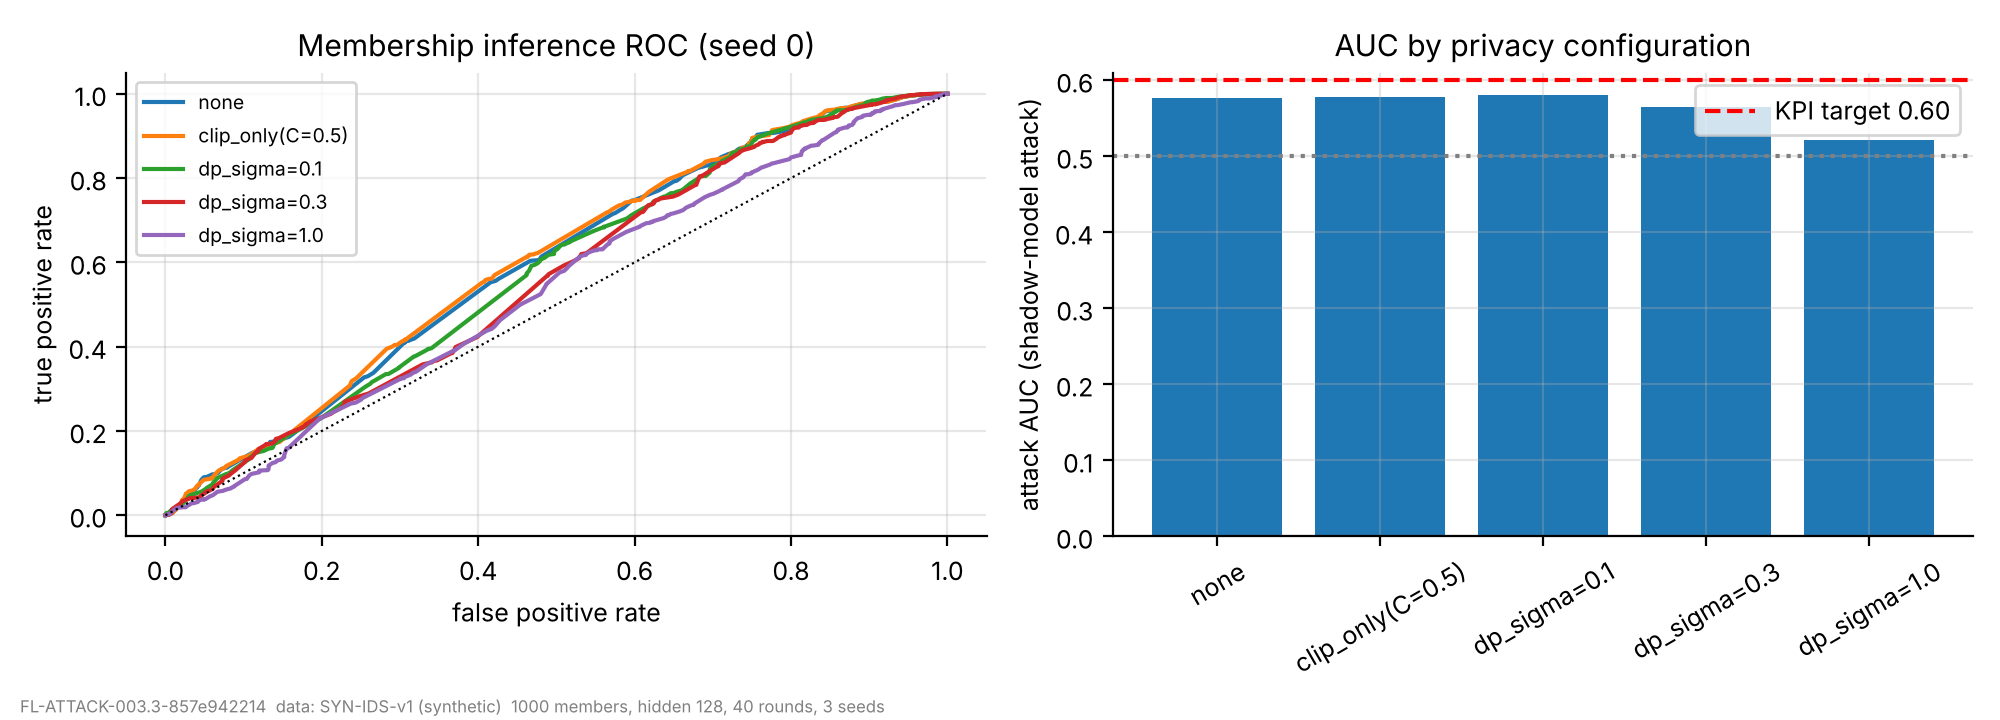

In [10]:
show_fig('task_3_3_membership_inference.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

AUC stays below 0.6 in this synthetic setting even undefended; reported with caveats about the regime.

In [11]:
d = pd.read_csv(RES / 'task_3_3_summary.csv'); print(d[['config','eps','auc','utility_acc']].round(3).to_string(index=False))

          config      eps   auc  utility_acc
            none      NaN 0.577        0.841
clip_only(C=0.5)      NaN 0.578        0.841
    dp_sigma=0.1 2311.778 0.581        0.839
    dp_sigma=0.3  321.528 0.564        0.827
    dp_sigma=1.0   48.802 0.521        0.754


## 16. Limitations
- Overfit regime on synthetic data; ε values are large and give little formal guarantee.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
KPI AUC<0.60 met in this regime; not a general claim.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`shokri2017`, `nasr2019`, `carlini2022`, `abadi2016`, `mironov2017` — details in `docs/fl_attack_003/references.md`.